# West Midlands EFDI — Spatial Weights and Neighbour Analysis (Python)

**Project folder:** `D:\Spatial Data Analysis`  
**Input:** `efdi_wm_clean.gpkg`  
**Target projected CRS:** EPSG:27700 — British National Grid (metres)

Queen-contiguity neighbours, polygon area, and whether LSOAs with many neighbours tend to be smaller or larger.

> **Important:** run cells 1–3 first in a **freshly restarted kernel** (Kernel → Restart). The PROJ fix in section 1 only works if geopandas/pyproj have not been imported yet.

## 1. Check the Python environment

In [1]:
import sys
print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\ofosu\anaconda3\envs\dortmund-climate\python.exe
Python version: 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]


## 1b. Fix PROJ / GDAL paths (cures `CRSError: no database context specified`)

This clears stale `PROJ_LIB` values (PostGIS, QGIS, etc.), finds the `proj.db` inside this conda environment, and tests that EPSG:27700 resolves. Run it **before** importing geopandas.

In [2]:
import os
from pathlib import Path

prefix = Path(os.environ.get("CONDA_PREFIX") or Path(sys.executable).parent)
lib = prefix / "Library"

# This environment's DLLs first
os.environ["PATH"] = str(lib / "bin") + os.pathsep + os.environ.get("PATH", "")

# Remove stale values left by other software
for var in ("PROJ_LIB", "PROJ_DATA", "GDAL_DATA"):
    os.environ.pop(var, None)

def first_existing(candidates, marker):
    for c in candidates:
        if (c / marker).exists():
            return c
    return None

proj_dir = first_existing([
    lib / "share" / "proj",
    prefix / "share" / "proj",
    prefix / "Lib" / "site-packages" / "pyproj" / "proj_dir" / "share" / "proj",
], "proj.db")
gdal_dir = first_existing([lib / "share" / "gdal", prefix / "share" / "gdal"], "gcs.csv")

if proj_dir is None:
    raise RuntimeError(
        "proj.db not found in this conda environment. Repair with:\n"
        "conda install -c conda-forge --force-reinstall proj pyproj fiona gdal geopandas"
    )

os.environ["PROJ_LIB"] = str(proj_dir)
os.environ["PROJ_DATA"] = str(proj_dir)
if gdal_dir is not None:
    os.environ["GDAL_DATA"] = str(gdal_dir)

import pyproj
pyproj.datadir.set_data_dir(str(proj_dir))

print("PROJ data dir:", pyproj.datadir.get_data_dir())
print("GDAL_DATA    :", os.environ.get("GDAL_DATA"))
print("CRS self-test:", pyproj.CRS.from_epsg(27700).name)   # expect: OSGB36 / British National Grid

PROJ data dir: C:\Users\ofosu\anaconda3\envs\dortmund-climate\Library\share\proj
GDAL_DATA    : None
CRS self-test: OSGB36 / British National Grid


c:\Users\ofosu\anaconda3\envs\dortmund-climate\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [3]:
required = ["geopandas", "libpysal", "esda", "pandas", "numpy", "matplotlib", "shapely"]

missing = []
for package in required:
    try:
        __import__(package)
        print(f"OK: {package}")
    except ImportError:
        missing.append(package)
        print(f"MISSING: {package}")

if missing:
    print("\nInstall missing packages in this environment, for example:")
    print("conda install -c conda-forge geopandas pysal pandas numpy matplotlib")
else:
    print("\nAll required packages are available.")

OK: geopandas
OK: libpysal
OK: esda
OK: pandas
OK: numpy
OK: matplotlib
OK: shapely

All required packages are available.


## 2. Import the packages

In [4]:
import geopandas as gpd
import libpysal
from libpysal.weights import Queen
import esda
import shapely
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

print("GeoPandas:", gpd.__version__)
print("libpysal:", libpysal.__version__)
print("esda:", esda.__version__)

GeoPandas: 1.2.0
libpysal: 4.15.1
esda: 2.10.0


## 3. Read the West Midlands dataset

In [5]:
project_dir = Path(r"D:\Spatial Data Analysis")
data_path = project_dir / "efdi_wm_clean.gpkg"

print("File exists:", data_path.exists())

food = gpd.read_file(data_path, engine="fiona")
food.head()

Cannot find header.dxf (GDAL_DATA is not defined)


File exists: True


,lsoa01cd,lsoa01nm,efdi,efdi_decil,imd_rank,house_pric,veg_cov,res_mob,geometry
0,E01009143,Birmingham 059B,38.30457,1,765,220000.0,0.810,0.084,"MULTIPOLYGON (((405342.998 286770.002, 405353...."
1,E01009145,Birmingham 060D,18.79994,6,10049,230747.5,0.924,0.143,"MULTIPOLYGON (((403486.646 287261.011, 403497...."
2,E01009146,Birmingham 059D,26.37110,3,3785,271875.0,0.512,0.201,"MULTIPOLYGON (((406107.117 286605.7, 406086.00..."
3,E01009147,Birmingham 060E,18.25160,6,2695,339150.0,0.849,0.172,"MULTIPOLYGON (((403193.486 286134.974, 403181...."
4,E01009151,Birmingham 053A,26.51394,3,4545,145500.0,0.446,0.082,"MULTIPOLYGON (((403690.406 287732.187, 403710...."


In [6]:
print("Rows:", len(food))
print(food.columns.tolist())
food.info()

Rows: 2365
['lsoa01cd', 'lsoa01nm', 'efdi', 'efdi_decil', 'imd_rank', 'house_pric', 'veg_cov', 'res_mob', 'geometry']
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 2365 entries, 0 to 2364
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   lsoa01cd    2365 non-null   str     
 1   lsoa01nm    2365 non-null   str     
 2   efdi        2365 non-null   float64 
 3   efdi_decil  2365 non-null   int64   
 4   imd_rank    2365 non-null   int64   
 5   house_pric  2334 non-null   float64 
 6   veg_cov     2320 non-null   float64 
 7   res_mob     2365 non-null   float64 
 8   geometry    2365 non-null   geometry
dtypes: float64(4), geometry(1), int64(2), str(2)
memory usage: 166.4 KB


## 4. Check the coordinate reference system (CRS)

In [7]:
print("Original CRS:", food.crs)
print("CRS name:", food.crs.name)
print("Authority:", food.crs.to_authority())
print("EPSG (min_confidence=0):", food.crs.to_epsg(min_confidence=0))

if food.crs is None:
    raise ValueError("The dataset has no CRS defined. Identify its true CRS before assigning one.")

food = food.to_crs(epsg=27700)
print("Analysis CRS:", food.crs)

Original CRS: EPSG:27700
CRS name: OSGB36 / British National Grid
Authority: ('EPSG', '27700')
EPSG (min_confidence=0): 27700
Analysis CRS: EPSG:27700


## 5. Check geometry quality

In [8]:
possible_id_fields = ["lsoa01cd", "LSOA11CD", "lsoa11cd", "LSOA_CODE", "lsoa_code"]
id_field = next((c for c in possible_id_fields if c in food.columns), None)
print("ID field:", id_field)

print("Rows before geometry checks:", len(food))
print("Missing geometries:", int(food.geometry.isna().sum()))
print("Empty geometries:", int(food.geometry.is_empty.sum()))
print("Invalid geometries:", int((~food.geometry.is_valid).sum()))
print(food.geom_type.value_counts())

ID field: lsoa01cd
Rows before geometry checks: 2365
Missing geometries: 0
Empty geometries: 0
Invalid geometries: 5
MultiPolygon    2365
Name: count, dtype: int64


In [ ]:
invalid_geometries = food.loc[~food.geometry.is_valid].copy()
if len(invalid_geometries):
    invalid_geometries["invalid_reason"] = shapely.is_valid_reason(invalid_geometries.geometry.values)
    display(invalid_geometries[([id_field] if id_field else []) + ["invalid_reason"]])
else:
    print("No invalid geometries.")

In [10]:
food_analysis = food.loc[food.geometry.notna() & ~food.geometry.is_empty].copy()

invalid_mask = ~food_analysis.geometry.is_valid
if invalid_mask.any():
    repaired = shapely.make_valid(food_analysis.loc[invalid_mask, "geometry"].values)
    food_analysis.loc[invalid_mask, "geometry"] = gpd.GeoSeries(
        repaired, index=food_analysis.index[invalid_mask], crs=food_analysis.crs
    )

print("Rows used for geometry analysis:", len(food_analysis))
print("Remaining invalid geometries:", int((~food_analysis.geometry.is_valid).sum()))

Rows used for geometry analysis: 2365
Remaining invalid geometries: 0


## 6. Create Queen-contiguity spatial weights

In [12]:
if id_field:
    ids = food_analysis[id_field].astype(str).tolist()
    if pd.Series(ids).duplicated().any():
        raise ValueError(f"{id_field} contains duplicate IDs; choose a unique identifier.")
    w_queen = Queen.from_dataframe(food_analysis, ids=ids)
else:
    w_queen = Queen.from_dataframe(food_analysis)

cards = np.array(list(w_queen.cardinalities.values()))

python_summary = {
    "type": "Queen contiguity (order 1)",
    "symmetry": "symmetric" if len(w_queen.asymmetry()) == 0 else "asymmetric",
    "id variable": id_field if id_field else "row index",
    "# observations": w_queen.n,
    "min neighbors": int(cards.min()),
    "max neighbors": int(cards.max()),
    "mean neighbors": round(float(cards.mean()), 2),
    "median neighbors": float(np.median(cards)),
    "% non-zero": round(w_queen.pct_nonzero, 2),
    "islands (zero neighbours)": len(w_queen.islands),
}

geoda_summary = {
    "# observations": 2365,
    "min neighbors": 1,
    "max neighbors": 21,
    "mean neighbors": 5.80,
    "median neighbors": 6.00,
    "% non-zero": 0.25,
    "islands (zero neighbours)": 0,   # GeoDa min neighbors = 1
}

print("PYTHON WEIGHTS SUMMARY")
print("-" * 45)
for k, v in python_summary.items():
    print(f"{k:28s}{v}")

comparison = pd.DataFrame({
    "GeoDa": pd.Series(geoda_summary),
    "Python": pd.Series({k: python_summary[k] for k in geoda_summary}),
})
comparison["match"] = np.isclose(
    comparison["GeoDa"].astype(float), comparison["Python"].astype(float), atol=0.005
)
print("\nCOMPARISON WITH GEODA (wm_queen.gal)")
comparison

PYTHON WEIGHTS SUMMARY
---------------------------------------------
type                        Queen contiguity (order 1)
symmetry                    symmetric
id variable                 lsoa01cd
# observations              2365
min neighbors               1
max neighbors               21
mean neighbors              5.8
median neighbors            6.0
% non-zero                  0.25
islands (zero neighbours)   0

COMPARISON WITH GEODA (wm_queen.gal)


,GeoDa,Python,match
# observations,2365.00,2365.00,True
min neighbors,1.00,1.00,True
max neighbors,21.00,21.00,True
mean neighbors,5.80,5.80,True
median neighbors,6.00,6.00,True
% non-zero,0.25,0.25,True
islands (zero neighbours),0.00,0.00,True


In [13]:
gal_path = project_dir / "wm_queen.gal"          # adjust if it is saved elsewhere
w_geoda = libpysal.io.open(str(gal_path)).read()

geoda_nb = {str(k): sorted(str(n) for n in v) for k, v in w_geoda.neighbors.items()}
python_nb = {str(k): sorted(str(n) for n in v) for k, v in w_queen.neighbors.items()}

print("IDs only in GeoDa :", len(set(geoda_nb) - set(python_nb)))
print("IDs only in Python:", len(set(python_nb) - set(geoda_nb)))

diff = [k for k in geoda_nb if k in python_nb and geoda_nb[k] != python_nb[k]]
print("LSOAs with different neighbour lists:", len(diff))
if diff:
    k = diff[0]
    print("Example:", k, "\n GeoDa :", geoda_nb[k], "\n Python:", python_nb[k])

IDs only in GeoDa : 0
IDs only in Python: 0
LSOAs with different neighbour lists: 0


In [15]:
neighbour_counts = pd.Series(w_queen.cardinalities, name="neighbours")

food_analysis = food_analysis.copy()
food_analysis["_weights_id"] = (
    food_analysis[id_field].astype(str) if id_field else food_analysis.index
)
food_analysis["neighbours"] = (
    food_analysis["_weights_id"].map(neighbour_counts).fillna(0).astype(int)
)

food_analysis[["neighbours"]].describe()

,neighbours
count,2365.000000
mean,5.802960
std,2.004245
min,1.000000
25%,5.000000
50%,6.000000
75%,7.000000
max,21.000000


## 7. Inspect the Queen weights

In [16]:
print("Minimum neighbours:", int(food_analysis["neighbours"].min()))
print("Maximum neighbours:", int(food_analysis["neighbours"].max()))
print("Mean neighbours:", food_analysis["neighbours"].mean())
print("Median neighbours:", food_analysis["neighbours"].median())
print("Islands:", int((food_analysis["neighbours"] == 0).sum()))

frequency = (
    food_analysis["neighbours"].value_counts().sort_index()
    .rename_axis("number_of_neighbours").reset_index(name="number_of_lsoas")
)
frequency["percent"] = 100 * frequency["number_of_lsoas"] / len(food_analysis)
frequency

Minimum neighbours: 1
Maximum neighbours: 21
Mean neighbours: 5.802959830866808
Median neighbours: 6.0
Islands: 0


,number_of_neighbours,number_of_lsoas,percent
0,1,9,0.380550
1,2,39,1.649049
2,3,136,5.750529
3,4,378,15.983087
4,5,583,24.651163
5,6,546,23.086681
6,7,298,12.600423
7,8,210,8.879493
8,9,71,3.002114
9,10,33,1.395349


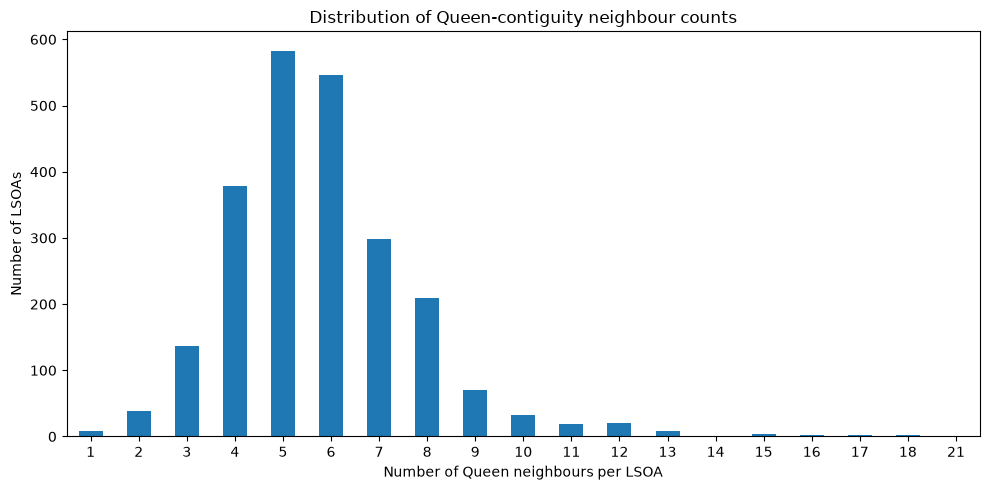

In [17]:
ax = frequency.plot(x="number_of_neighbours", y="number_of_lsoas", kind="bar", legend=False, figsize=(10, 5))
ax.set_xlabel("Number of Queen neighbours per LSOA")
ax.set_ylabel("Number of LSOAs")
ax.set_title("Distribution of Queen-contiguity neighbour counts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Calculate polygon area in square kilometres

In [18]:
food_analysis["area_km2"] = food_analysis.geometry.area / 1_000_000
food_analysis[["area_km2", "neighbours"]].describe()

,area_km2,neighbours
count,2365.000000,2365.000000
mean,1.820563,5.802960
std,5.501953,2.004245
min,0.082788,1.000000
25%,0.281804,5.000000
50%,0.393667,6.000000
75%,0.699716,7.000000
max,58.793332,21.000000


## 9. LSOAs with the highest number of neighbours

In [20]:
top20 = food_analysis.sort_values(["neighbours", "area_km2"], ascending=[False, False]).head(20)

top20[["lsoa01cd", "lsoa01nm", "neighbours", "area_km2"]].round({"area_km2": 2}).reset_index(drop=True)

,lsoa01cd,lsoa01nm,neighbours,area_km2
0,E01031213,Stratford-on-Avon 001A,21,37.14
1,E01029488,Lichfield 012A,18,43.09
2,E01032169,Bromsgrove 002D,18,17.56
3,E01029652,South Staffordshire 014D,17,14.51
4,E01029395,Cannock Chase 013B,17,10.75
5,E01032432,Wyre Forest 001B,16,18.54
6,E01029645,South Staffordshire 013A,16,16.88
7,E01029632,South Staffordshire 007A,16,7.56
8,E01031308,Warwick 005G,15,31.50
9,E01032176,Bromsgrove 002E,15,26.16


## 10. Map the neighbour counts

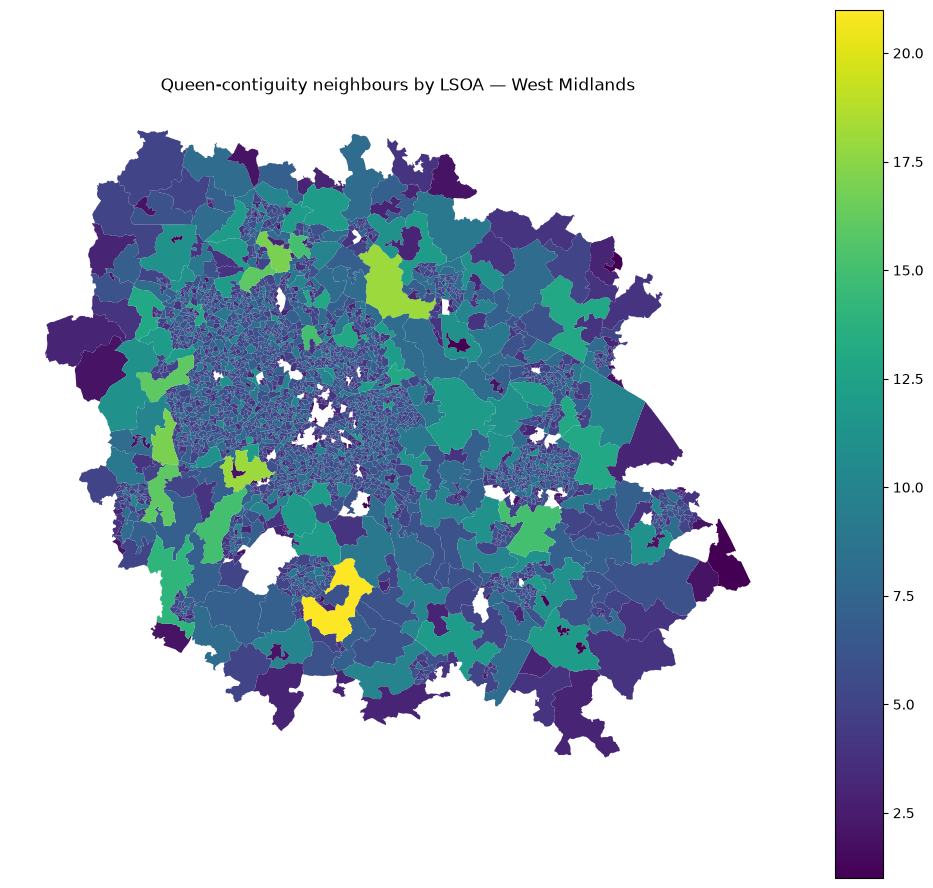

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
food_analysis.plot(column="neighbours", cmap="viridis", legend=True, linewidth=0.05, ax=ax,
                   missing_kwds={"color": "lightgrey", "label": "Missing"})
ax.set_title("Queen-contiguity neighbours by LSOA — West Midlands")
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 11. Map the LSOAs with the maximum neighbour count

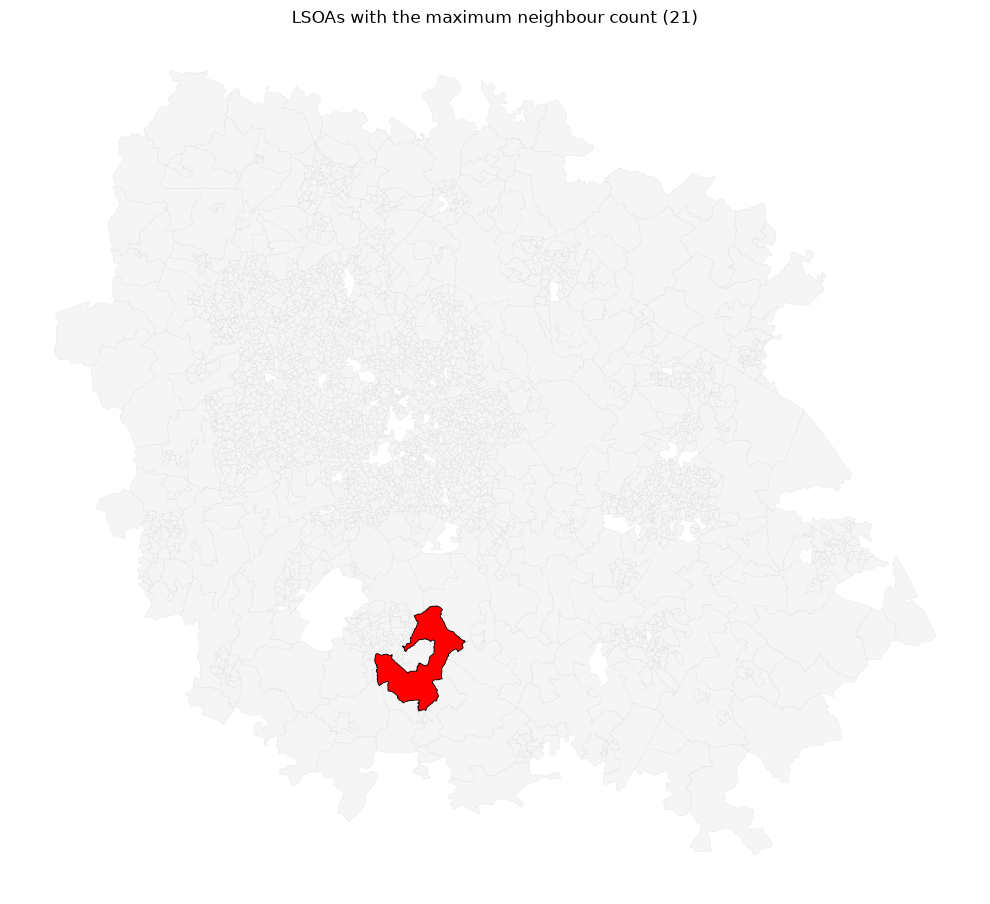

Number of LSOAs tied at the maximum: 1


In [22]:
max_neighbours = food_analysis["neighbours"].max()
max_lsoas = food_analysis.loc[food_analysis["neighbours"] == max_neighbours]

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
food_analysis.plot(ax=ax, color="whitesmoke", edgecolor="lightgrey", linewidth=0.15)
max_lsoas.plot(ax=ax, color="red", edgecolor="black", linewidth=0.6)
ax.set_title(f"LSOAs with the maximum neighbour count ({max_neighbours})")
ax.set_axis_off()
plt.tight_layout()
plt.show()

print("Number of LSOAs tied at the maximum:", len(max_lsoas))

## 12. Compare neighbour count with polygon area

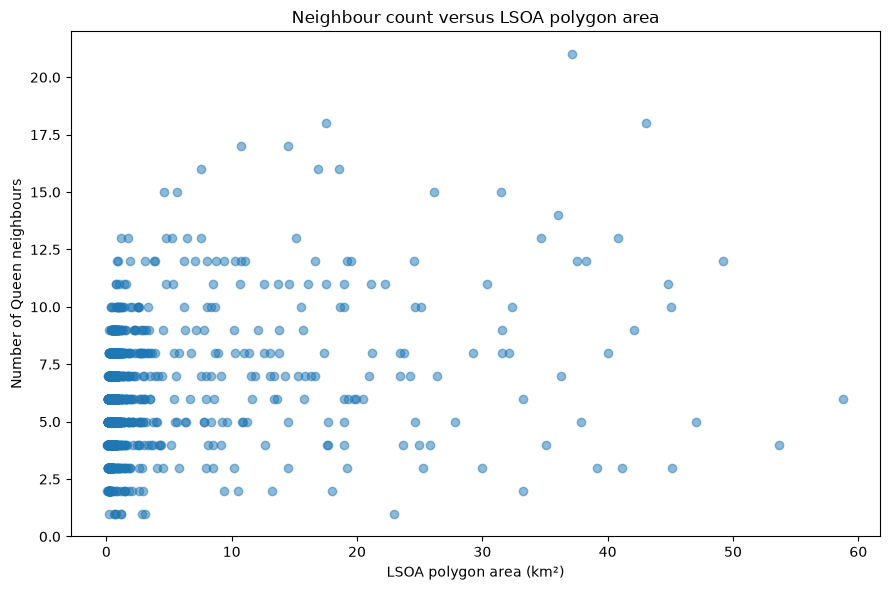

In [23]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(food_analysis["area_km2"], food_analysis["neighbours"], alpha=0.5)
ax.set_xlabel("LSOA polygon area (km²)")
ax.set_ylabel("Number of Queen neighbours")
ax.set_title("Neighbour count versus LSOA polygon area")
plt.tight_layout()
plt.show()

In [24]:
corr = food_analysis[["area_km2", "neighbours"]].corr(method="spearman").iloc[0, 1]
print("Spearman correlation:", corr)

Spearman correlation: 0.35051243928757064


## 13. Compare polygon area across neighbour-count groups

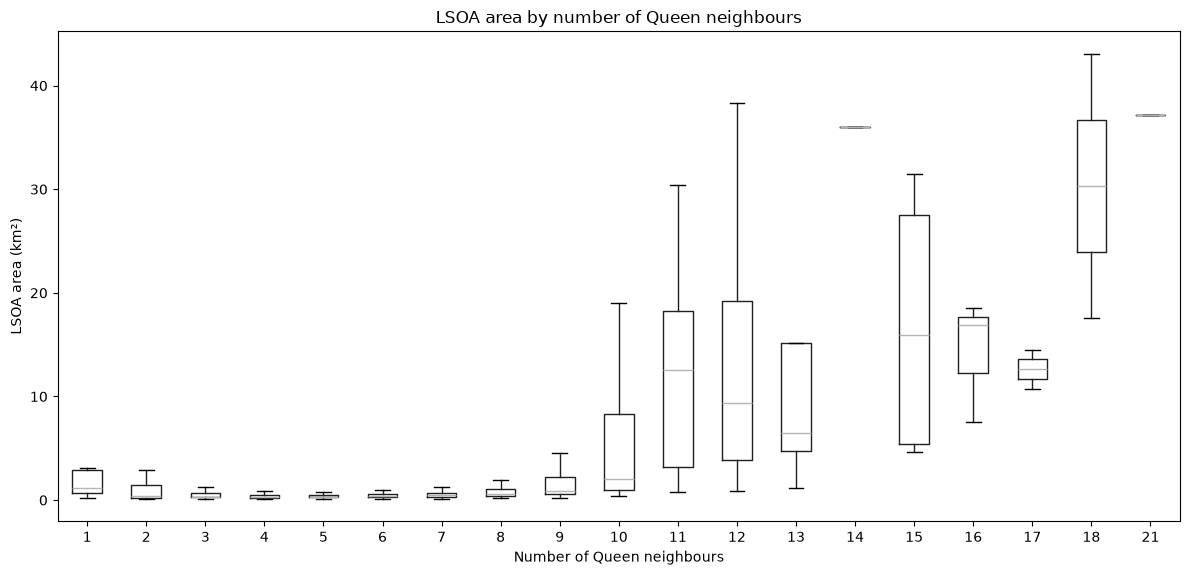

In [25]:
fig, ax = plt.subplots(figsize=(12, 6))
food_analysis.boxplot(column="area_km2", by="neighbours", ax=ax, grid=False, showfliers=False)
ax.set_xlabel("Number of Queen neighbours")
ax.set_ylabel("LSOA area (km²)")
ax.set_title("LSOA area by number of Queen neighbours")
fig.suptitle("")
plt.tight_layout()
plt.show()

In [30]:
area_by_neighbours = (
    food_analysis.groupby("neighbours")["area_km2"]
    .agg(["count", "mean", "median", "min", "max"]).reset_index()
)
area_by_neighbours

,neighbours,count,mean,median,min,max
0,1,9,3.720244,1.132263,0.219780,22.941510
1,2,39,2.757948,0.360040,0.082788,33.255993
2,3,136,2.319343,0.336947,0.105839,45.149128
3,4,378,1.143115,0.313643,0.084135,53.632127
4,5,583,0.939078,0.337624,0.104338,47.009364
5,6,546,0.989684,0.381521,0.114492,58.793332
6,7,298,1.561122,0.447962,0.138093,36.313986
7,8,210,2.296208,0.621258,0.196513,40.053521
8,9,71,3.017535,0.899316,0.218322,42.078513
9,10,33,7.347984,2.043611,0.352244,45.020794


## 14. Optional: group neighbour counts into bands

In [ ]:
bins = [-1, 3, 6, 9, np.inf]
labels = ["0–3", "4–6", "7–9", "10+"]
food_analysis["neighbour_band"] = pd.cut(food_analysis["neighbours"], bins=bins, labels=labels)

band_summary = (
    food_analysis.groupby("neighbour_band", observed=False)["area_km2"]
    .agg(["count", "mean", "median", "min", "max"]).reset_index()
)
band_summary

## 15. Check EFDI missing values

In [31]:
if "efdi" not in food_analysis.columns:
    print("The column 'efdi' was not found. Check the exact field name:")
    print(food_analysis.columns.tolist())
else:
    print("EFDI missing values:", int(food_analysis["efdi"].isna().sum()))
    print("EFDI non-missing values:", int(food_analysis["efdi"].notna().sum()))
    print(food_analysis["efdi"].describe())

EFDI missing values: 0
EFDI non-missing values: 2365
count    2365.000000
mean       21.745766
std         8.529239
min         3.509750
25%        15.362260
50%        20.304060
75%        27.492800
max        51.629010
Name: efdi, dtype: float64


In [32]:
# Check the range of EFDI
print("EFDI minimum:", food_analysis["efdi"].min())
print("EFDI maximum:", food_analysis["efdi"].max())
print("Unique EFDI values:", food_analysis["efdi"].nunique())

# Check the EFDI decile range
print("\nEFDI decile minimum:", food_analysis["efdi_decil"].min())
print("EFDI decile maximum:", food_analysis["efdi_decil"].max())

# Display the distinct decile categories
print("\nEFDI decile categories:")
print(sorted(food_analysis["efdi_decil"].dropna().unique()))

EFDI minimum: 3.50975
EFDI maximum: 51.62901
Unique EFDI values: 2362

EFDI decile minimum: 1
EFDI decile maximum: 10

EFDI decile categories:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [33]:
food_analysis[
    ["lsoa01cd", "lsoa01nm", "efdi", "efdi_decil"]
].head(20)

,lsoa01cd,lsoa01nm,efdi,efdi_decil
0,E01009143,Birmingham 059B,38.30457,1
1,E01009145,Birmingham 060D,18.79994,6
2,E01009146,Birmingham 059D,26.37110,3
3,E01009147,Birmingham 060E,18.25160,6
4,E01009151,Birmingham 053A,26.51394,3
5,E01009152,Birmingham 053B,29.58538,2
6,E01009153,Birmingham 053C,29.22965,3
7,E01009155,Birmingham 125B,32.66081,2
8,E01009157,Birmingham 125D,28.31406,3
9,E01009158,Birmingham 129A,25.07252,4


In [34]:
food_analysis.loc[
    food_analysis["efdi"].between(50, 52),
    ["lsoa01cd", "lsoa01nm", "efdi", "efdi_decil"]
]

,lsoa01cd,lsoa01nm,efdi,efdi_decil
335,E01009203,Birmingham 043C,51.62901,1


In [35]:
food_analysis.groupby("efdi_decil").agg(
    count=("efdi", "count"),
    min_efdi=("efdi", "min"),
    mean_efdi=("efdi", "mean"),
    median_efdi=("efdi", "median"),
    max_efdi=("efdi", "max")
)

,count,min_efdi,mean_efdi,median_efdi,max_efdi
efdi_decil,,,,,
1,174,35.96617,39.775951,39.278710,51.62901
2,303,29.28210,32.258261,32.130480,35.95242
3,268,25.12626,27.139175,27.140480,29.24376
4,240,22.21850,23.622368,23.716430,25.09949
5,295,19.53879,20.761027,20.705440,22.20656
6,261,17.26515,18.383238,18.449220,19.50937
7,264,15.04862,16.168383,16.160385,17.26301
8,231,12.63408,13.888439,13.939890,15.04455
9,231,9.58830,11.265117,11.376740,12.61259


## 16. Global Moran's I for EFDI

Weights are rebuilt on exactly the non-missing EFDI rows.

In [36]:
if "efdi" in food_analysis.columns:
    food_efdi = food_analysis.loc[food_analysis["efdi"].notna()].copy()

    if id_field:
        w_efdi = Queen.from_dataframe(food_efdi, ids=food_efdi[id_field].astype(str).tolist())
    else:
        w_efdi = Queen.from_dataframe(food_efdi)

    w_efdi.transform = "R"
    y = food_efdi["efdi"].to_numpy(dtype=float)

    np.random.seed(12345)
    moran_global = esda.Moran(y, w_efdi, permutations=999)
    print("Global Moran's I:", moran_global.I)
    print("Expected I:", moran_global.EI)
    print("Permutation p-value:", moran_global.p_sim)
else:
    print("Skipping Moran's I: no 'efdi' column.")

Global Moran's I: 0.4531533369125695
Expected I: -0.00042301184433164127
Permutation p-value: 0.001


## 17. Local Moran's I (LISA) for EFDI

`q`: 1 = High–High, 2 = Low–High, 3 = Low–Low, 4 = High–Low.

In [37]:
print(moran_global.sim[:20])

[-0.00979057 -0.01342518 -0.0240996  -0.01370189  0.00415704 -0.01025553
  0.01479752 -0.00388696  0.00106619 -0.00864083  0.01525629 -0.00076507
  0.02058992 -0.0330995   0.01626055  0.01021081  0.00078227  0.01481722
  0.00113361 -0.01035972]


In [39]:
print("Original Moran's I:", moran_global.I)
print("Randomisation mean:", moran_global.sim.mean())
print("Randomisation minimum:", moran_global.sim.min())
print("Randomisation maximum:", moran_global.sim.max())
print("Permutation p-value:", moran_global.p_sim)

Original Moran's I: 0.4531533369125695
Randomisation mean: -0.0006537398465001026
Randomisation minimum: -0.04055537192720504
Randomisation maximum: 0.040912693233644874
Permutation p-value: 0.001


In [41]:

import numpy as np
import esda
import pandas as pd

# Three permutation levels
permutation_levels = {
    "Low": 99,
    "Medium": 999,
    "High": 9999
}

results = []

for level, n_permutations in permutation_levels.items():

    np.random.seed(42)

    moran_result = esda.Moran(
        y,
        w_efdi,
        permutations=n_permutations
    )

    results.append({
        "Level": level,
        "Permutations": n_permutations,
        "Observed Moran's I": moran_result.I,
        "Expected Moran's I": moran_result.EI,
        "Permutation p-value": moran_result.p_sim,
        "Randomisation mean": moran_result.sim.mean(),
        "Randomisation minimum": moran_result.sim.min(),
        "Randomisation maximum": moran_result.sim.max()
    })

comparison = pd.DataFrame(results)

print(comparison.to_string(index=False))


 Level  Permutations  Observed Moran's I  Expected Moran's I  Permutation p-value  Randomisation mean  Randomisation minimum  Randomisation maximum
   Low            99            0.453153           -0.000423               0.0100           -0.001350              -0.028029               0.024580
Medium           999            0.453153           -0.000423               0.0010           -0.001294              -0.037501               0.046035
  High          9999            0.453153           -0.000423               0.0001           -0.000625              -0.044984               0.046035


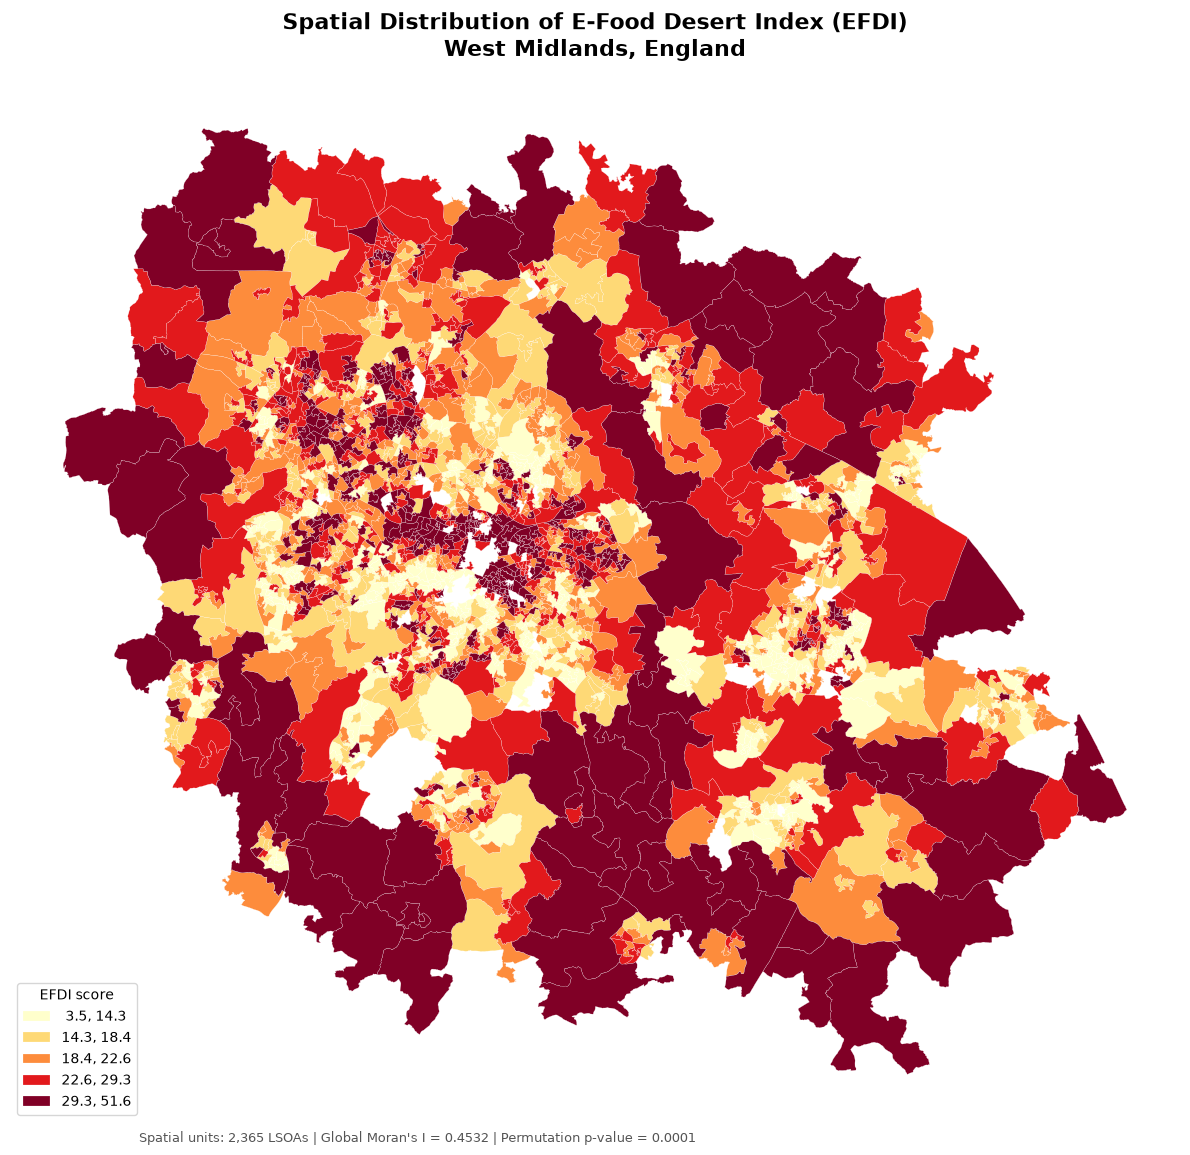

In [49]:

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import mapclassify

# --------------------------------------------------
# GLOBAL EFDI DISTRIBUTION MAP
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 12))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Plot EFDI values across all West Midlands LSOAs
food_global.plot(
    column="efdi",
    cmap="YlOrRd",
    scheme="Quantiles",
    k=5,
    linewidth=0.15,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "title": "EFDI score",
        "loc": "lower left",
        "fmt": "{:.1f}"
    },
    ax=ax,
    missing_kwds={
        "color": "#EEEEEE",
        "label": "Missing data"
    }
)

# Title
ax.set_title(
    "Spatial Distribution of E-Food Desert Index (EFDI)\n"
    "West Midlands, England",
    fontsize=16,
    fontweight="bold",
    pad=18
)

# Remove axes
ax.set_axis_off()

# Add source note
fig.text(
    0.12, 0.04,
    "Spatial units: 2,365 LSOAs | "
    "Global Moran's I = 0.4532 | "
    "Permutation p-value = 0.0001",
    fontsize=9,
    color="#555555"
)

plt.tight_layout()

# Save
plt.savefig(
    "Global_Morans_I_EFDI_Distribution_Map.png",
    dpi=300,
    facecolor="white",
    bbox_inches="tight"
)

plt.show()


In [50]:
food_analysis[
    ["lsoa01cd", "lsoa01nm", "efdi", "neighbours"]
].head(10)

,lsoa01cd,lsoa01nm,efdi,neighbours
0,E01009143,Birmingham 059B,38.30457,7
1,E01009145,Birmingham 060D,18.79994,10
2,E01009146,Birmingham 059D,26.37110,1
3,E01009147,Birmingham 060E,18.25160,6
4,E01009151,Birmingham 053A,26.51394,5
5,E01009152,Birmingham 053B,29.58538,6
6,E01009153,Birmingham 053C,29.22965,6
7,E01009155,Birmingham 125B,32.66081,2
8,E01009157,Birmingham 125D,28.31406,2
9,E01009158,Birmingham 129A,25.07252,5


In [51]:
food_analysis[
    ["lsoa01cd", "lsoa01nm", "efdi", "neighbours"]
].sort_values(
    "neighbours",
    ascending=False
).head(10)

,lsoa01cd,lsoa01nm,efdi,neighbours
2097,E01031213,Stratford-on-Avon 001A,17.37961,21
2256,E01032169,Bromsgrove 002D,15.34106,18
1742,E01029488,Lichfield 012A,36.82101,18
1723,E01029395,Cannock Chase 013B,18.56288,17
1823,E01029652,South Staffordshire 014D,15.49545,17
1619,E01032432,Wyre Forest 001B,30.80562,16
1803,E01029632,South Staffordshire 007A,15.91161,16
1816,E01029645,South Staffordshire 013A,26.71476,16
1751,E01029497,Lichfield 006E,21.21181,15
2263,E01032176,Bromsgrove 002E,25.57084,15


In [42]:
if "efdi" in food_analysis.columns:
    lisa = esda.Moran_Local(y, w_efdi, permutations=999, seed=12345)
    food_efdi["local_I"] = lisa.Is
    food_efdi["p_sim"] = lisa.p_sim
    food_efdi["quadrant"] = lisa.q
    display(food_efdi[["efdi", "local_I", "p_sim", "quadrant"]].head())
else:
    print("Skipping Local Moran's I: no 'efdi' column.")

,efdi,local_I,p_sim,quadrant
0,38.30457,-0.045696,0.479,4
1,18.79994,0.056698,0.289,3
2,26.37110,-0.772126,0.041,4
3,18.25160,0.418776,0.004,3
4,26.51394,0.310331,0.122,1


cluster
Not significant    1647
Low-Low             348
High-High           307
Low-High             32
High-Low             31
Name: count, dtype: int64


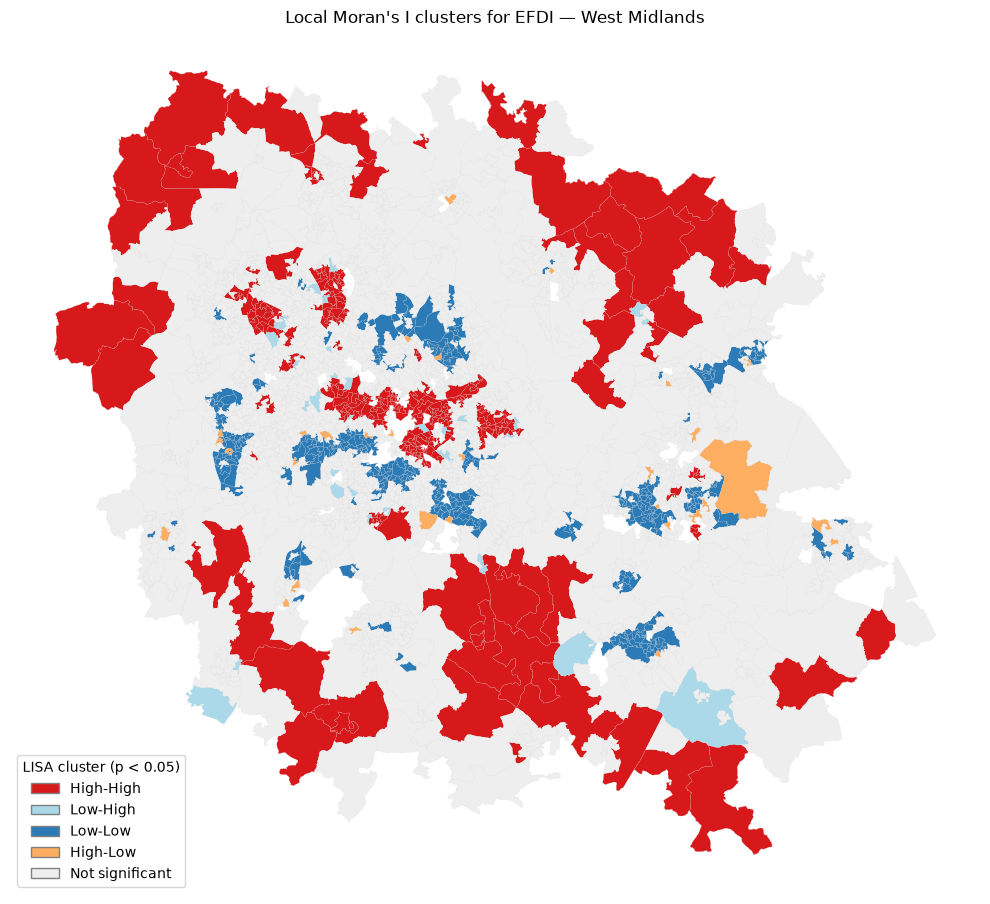

In [29]:
if "efdi" in food_analysis.columns:
    quad_names = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}
    quad_colors = {"High-High": "#d7191c", "Low-High": "#abd9e9", "Low-Low": "#2c7bb6",
                   "High-Low": "#fdae61", "Not significant": "#eeeeee"}

    food_efdi["cluster"] = np.where(
        food_efdi["p_sim"] < 0.05, food_efdi["quadrant"].map(quad_names), "Not significant"
    )
    print(food_efdi["cluster"].value_counts())

    fig, ax = plt.subplots(figsize=(10, 10))
    for name, colour in quad_colors.items():
        subset = food_efdi[food_efdi["cluster"] == name]
        if len(subset):
            subset.plot(ax=ax, color=colour, edgecolor="lightgrey", linewidth=0.1)
    ax.legend(handles=[mpatches.Patch(facecolor=c, edgecolor="grey", label=n)
                       for n, c in quad_colors.items()],
              title="LISA cluster (p < 0.05)", loc="lower left")
    ax.set_title("Local Moran's I clusters for EFDI — West Midlands")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

## 18. Save analysis outputs (optional)

In [ ]:
output_path = project_dir / "efdi_wm_neighbour_analysis.gpkg"

out = food_analysis.drop(columns=["_weights_id"]).copy()
out["neighbour_band"] = out["neighbour_band"].astype(str)
out.to_file(output_path, layer="neighbour_analysis", driver="GPKG")

if "efdi" in food_analysis.columns:
    food_efdi.drop(columns=["_weights_id"]).assign(
        neighbour_band=lambda d: d["neighbour_band"].astype(str)
    ).to_file(output_path, layer="efdi_lisa", driver="GPKG")

print("Saved:", output_path)

## 19. Comparison checklist: Python versus R

1. Same cleaned GeoPackage and same number of observations.
2. EPSG:27700 for area and distance.
3. Queen contiguity (edge **or** corner), not Rook.
4. Same geometry repair/exclusion decisions.
5. Same LSOA identifiers and observation order.
6. Neighbour counts, min, max, mean, median and island counts agree.
7. Polygon areas agree (allowing tiny floating-point differences).
8. For Moran's I: same non-missing EFDI rows, weights, row-standardisation and permutations.

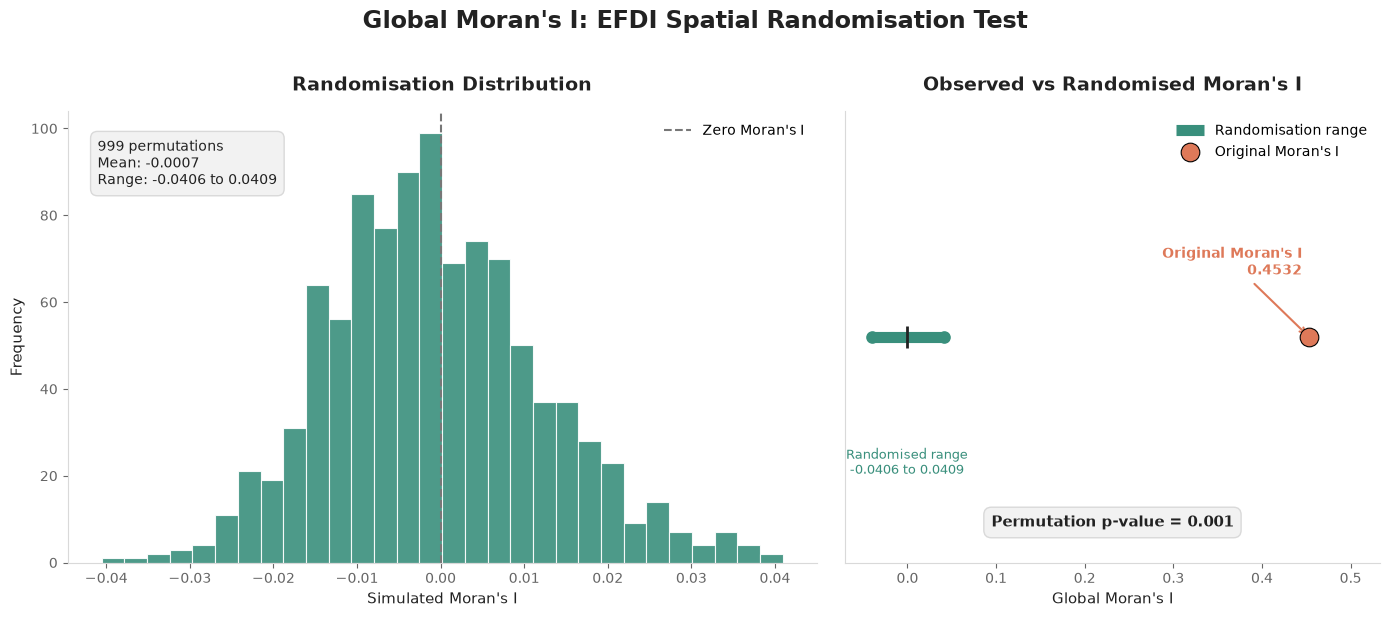

In [40]:

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Extract results from the Moran's I analysis
# --------------------------------------------------
simulated = moran_global.sim

observed_i = moran_global.I
random_mean = simulated.mean()
random_min = simulated.min()
random_max = simulated.max()
p_value = moran_global.p_sim

# --------------------------------------------------
# Colours
# --------------------------------------------------
background = "#FFFFFF"
text_color = "#222222"
muted_color = "#666666"
hist_color = "#398F7C"
observed_color = "#DE7959"
reference_color = "#777777"

# --------------------------------------------------
# Create figure with two visualisations
# --------------------------------------------------
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 6),
    gridspec_kw={"width_ratios": [1.4, 1]}
)

fig.patch.set_facecolor(background)

for ax in (ax1, ax2):
    ax.set_facecolor(background)

# --------------------------------------------------
# VISUAL 1: Randomisation distribution
# --------------------------------------------------
ax1.hist(
    simulated,
    bins=30,
    color=hist_color,
    edgecolor="white",
    linewidth=0.8,
    alpha=0.9
)

# Reference line at zero
ax1.axvline(
    0,
    color=reference_color,
    linestyle="--",
    linewidth=1.5,
    label="Zero Moran's I"
)

ax1.set_title(
    "Randomisation Distribution",
    fontsize=14,
    fontweight="bold",
    color=text_color,
    pad=15
)

ax1.set_xlabel(
    "Simulated Moran's I",
    fontsize=11,
    color=text_color
)

ax1.set_ylabel(
    "Frequency",
    fontsize=11,
    color=text_color
)

ax1.text(
    0.04, 0.94,
    f"999 permutations\n"
    f"Mean: {random_mean:.4f}\n"
    f"Range: {random_min:.4f} to {random_max:.4f}",
    transform=ax1.transAxes,
    va="top",
    fontsize=10,
    color=text_color,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#F2F2F2",
        edgecolor="#D9D9D9"
    )
)

ax1.legend(frameon=False, loc="upper right")

# --------------------------------------------------
# VISUAL 2: Actual Moran's I vs randomised range
# --------------------------------------------------
ax2.hlines(
    y=1,
    xmin=random_min,
    xmax=random_max,
    color=hist_color,
    linewidth=8,
    label="Randomisation range"
)

# Randomisation minimum and maximum
ax2.scatter(
    [random_min, random_max],
    [1, 1],
    color=hist_color,
    s=65,
    zorder=3
)

# Randomisation mean
ax2.scatter(
    random_mean,
    1,
    color="#222222",
    marker="|",
    s=250,
    linewidths=2,
    zorder=4
)

# Original observed Moran's I
ax2.scatter(
    observed_i,
    1,
    color=observed_color,
    edgecolor="black",
    linewidth=0.8,
    s=180,
    zorder=5,
    label="Original Moran's I"
)

# Annotate observed value
ax2.annotate(
    f"Original Moran's I\n{observed_i:.4f}",
    xy=(observed_i, 1),
    xytext=(-5, 45),
    textcoords="offset points",
    ha="right",
    fontsize=10,
    fontweight="bold",
    color=observed_color,
    arrowprops=dict(
        arrowstyle="->",
        color=observed_color,
        linewidth=1.5
    )
)

# Annotate randomisation range
ax2.text(
    random_mean,
    0.83,
    f"Randomised range\n{random_min:.4f} to {random_max:.4f}",
    ha="center",
    va="top",
    fontsize=9,
    color=hist_color
)

ax2.set_title(
    "Observed vs Randomised Moran's I",
    fontsize=14,
    fontweight="bold",
    color=text_color,
    pad=15
)

ax2.set_xlabel(
    "Global Moran's I",
    fontsize=11,
    color=text_color
)

ax2.set_yticks([])
ax2.set_ylim(0.65, 1.35)
ax2.set_xlim(random_min - 0.03, observed_i + 0.08)

# P-value annotation
ax2.text(
    0.5, 0.08,
    f"Permutation p-value = {p_value:.3f}",
    transform=ax2.transAxes,
    ha="center",
    fontsize=11,
    fontweight="bold",
    color=text_color,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#F2F2F2",
        edgecolor="#D9D9D9"
    )
)

ax2.legend(
    loc="upper right",
    frameon=False
)

# --------------------------------------------------
# Overall formatting
# --------------------------------------------------
for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D9D9D9")
    ax.spines["bottom"].set_color("#D9D9D9")
    ax.tick_params(colors=muted_color)

fig.suptitle(
    "Global Moran's I: EFDI Spatial Randomisation Test",
    fontsize=17,
    fontweight="bold",
    color=text_color,
    y=1.02
)

plt.tight_layout()

# Save figure
plt.savefig(
    "Global_Morans_I_Randomisation_Analysis.png",
    dpi=300,
    facecolor=background,
    bbox_inches="tight"
)

plt.show()


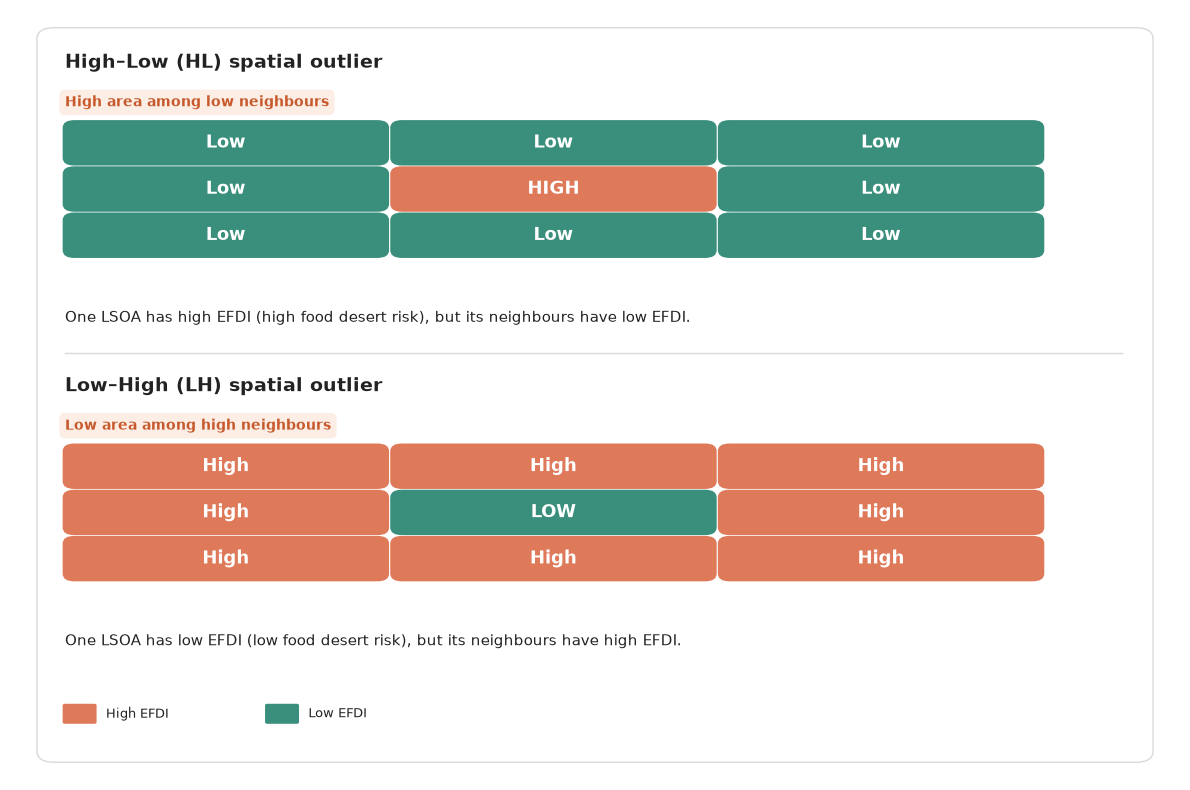

In [45]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# --------------------------------------------------
# Colours — WHITE BACKGROUND
# --------------------------------------------------
background = "#FFFFFF"
panel_color = "#FFFFFF"

high_color = "#DE7959"   # High EFDI
low_color = "#398F7C"    # Low EFDI

text_color = "#222222"
muted_color = "#666666"
border_color = "#D9D9D9"

# --------------------------------------------------
# Figure setup
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 8))

fig.patch.set_facecolor(background)
ax.set_facecolor(background)

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

# --------------------------------------------------
# Main panel
# --------------------------------------------------
panel = FancyBboxPatch(
    (0.25, 0.25),
    9.5,
    9.5,
    boxstyle="round,pad=0.02,rounding_size=0.15",
    facecolor=panel_color,
    edgecolor=border_color,
    linewidth=1
)

ax.add_patch(panel)

# --------------------------------------------------
# Function to draw a 3 x 3 neighbourhood
# --------------------------------------------------
def draw_neighbourhood(data, y_start):

    cell_width = 2.75
    cell_height = 0.55
    gap = 0.05
    x_start = 0.47

    for row_index, row in enumerate(data):

        for col_index, value in enumerate(row):

            x = x_start + col_index * (cell_width + gap)
            y = y_start - row_index * (cell_height + gap)

            # Case-insensitive colour selection
            colour = (
                high_color
                if value.upper() == "HIGH"
                else low_color
            )

            cell = FancyBboxPatch(
                (x, y),
                cell_width,
                cell_height,
                boxstyle="round,pad=0.02,rounding_size=0.10",
                facecolor=colour,
                edgecolor="none"
            )

            ax.add_patch(cell)

            ax.text(
                x + cell_width / 2,
                y + cell_height / 2,
                value,
                ha="center",
                va="center",
                fontsize=13,
                fontweight="bold",
                color="white"
            )

# --------------------------------------------------
# 1. HIGH-LOW (HL) SPATIAL OUTLIER
# --------------------------------------------------
ax.text(
    0.47, 9.25,
    "High–Low (HL) spatial outlier",
    fontsize=14,
    fontweight="bold",
    color=text_color
)

# Description badge
ax.text(
    0.47, 8.75,
    "High area among low neighbours",
    fontsize=10,
    fontweight="bold",
    color="#C75A2D",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="#FCEDE5",
        edgecolor="none"
    )
)

# One high EFDI LSOA surrounded by eight low EFDI LSOAs
high_low_data = [
    ["Low", "Low", "Low"],
    ["Low", "HIGH", "Low"],
    ["Low", "Low", "Low"]
]

draw_neighbourhood(high_low_data, 8.0)

ax.text(
    0.47, 5.95,
    "One LSOA has high EFDI (high food desert risk), "
    "but its neighbours have low EFDI.",
    fontsize=10.5,
    color=text_color
)

# --------------------------------------------------
# Divider
# --------------------------------------------------
ax.plot(
    [0.47, 9.5],
    [5.55, 5.55],
    color=border_color,
    linewidth=1
)

# --------------------------------------------------
# 2. LOW-HIGH (LH) SPATIAL OUTLIER
# --------------------------------------------------
ax.text(
    0.47, 5.05,
    "Low–High (LH) spatial outlier",
    fontsize=14,
    fontweight="bold",
    color=text_color
)

# Description badge
ax.text(
    0.47, 4.55,
    "Low area among high neighbours",
    fontsize=10,
    fontweight="bold",
    color="#C75A2D",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="#FCEDE5",
        edgecolor="none"
    )
)

# One low EFDI LSOA surrounded by eight high EFDI LSOAs
low_high_data = [
    ["High", "High", "High"],
    ["High", "LOW", "High"],
    ["High", "High", "High"]
]

draw_neighbourhood(low_high_data, 3.8)

ax.text(
    0.47, 1.75,
    "One LSOA has low EFDI (low food desert risk), "
    "but its neighbours have high EFDI.",
    fontsize=10.5,
    color=text_color
)

# --------------------------------------------------
# Legend
# --------------------------------------------------
ax.add_patch(
    FancyBboxPatch(
        (0.47, 0.75),
        0.25,
        0.22,
        boxstyle="round,pad=0.02",
        facecolor=high_color,
        edgecolor="none"
    )
)

ax.text(
    0.82, 0.86,
    "High EFDI",
    fontsize=9.5,
    color=text_color,
    va="center"
)

ax.add_patch(
    FancyBboxPatch(
        (2.2, 0.75),
        0.25,
        0.22,
        boxstyle="round,pad=0.02",
        facecolor=low_color,
        edgecolor="none"
    )
)

ax.text(
    2.55, 0.86,
    "Low EFDI",
    fontsize=9.5,
    color=text_color,
    va="center"
)

# --------------------------------------------------
# Display and save
# --------------------------------------------------
plt.tight_layout()

plt.savefig(
    "EFDI_Spatial_Outliers_White_Background.png",
    dpi=300,
    facecolor=background,
    bbox_inches="tight"
)

plt.show()


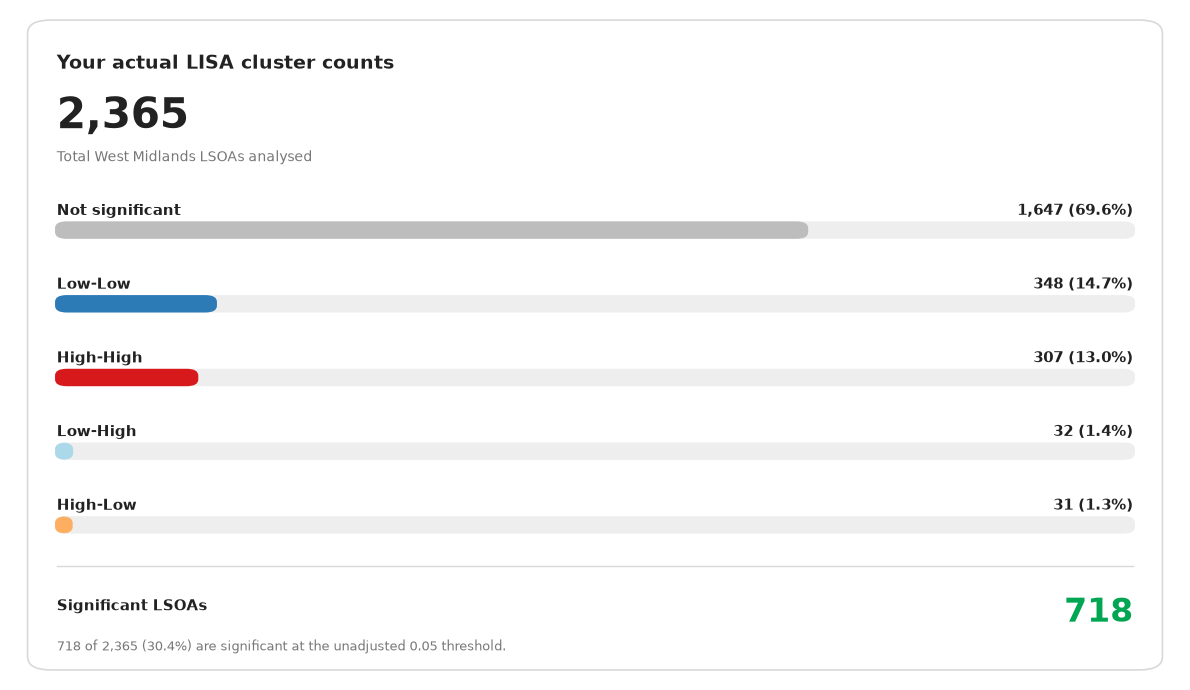

In [46]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# --------------------------------------------------
# LISA CLUSTER RESULTS
# --------------------------------------------------
total_lsoas = 2365

clusters = [
    ("Not significant", 1647, "#BDBDBD"),
    ("Low-Low", 348, "#2C7BB6"),
    ("High-High", 307, "#D7191C"),
    ("Low-High", 32, "#ABD9E9"),
    ("High-Low", 31, "#FDAE61")
]

significant_lsoas = 718

# --------------------------------------------------
# COLOURS — WHITE BACKGROUND
# --------------------------------------------------
background = "#FFFFFF"
text_color = "#222222"
muted_color = "#777777"
border_color = "#D9D9D9"
bar_background = "#EEEEEE"
success_color = "#00A651"

# --------------------------------------------------
# FIGURE SETUP
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 7))

fig.patch.set_facecolor(background)
ax.set_facecolor(background)

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

# --------------------------------------------------
# MAIN PANEL
# --------------------------------------------------
panel = FancyBboxPatch(
    (2, 2),
    96,
    96,
    boxstyle="round,pad=0.5,rounding_size=2",
    facecolor=background,
    edgecolor=border_color,
    linewidth=1.2
)

ax.add_patch(panel)

# --------------------------------------------------
# TITLE
# --------------------------------------------------
ax.text(
    4, 92,
    "Your actual LISA cluster counts",
    fontsize=14,
    fontweight="bold",
    color=text_color,
    va="center"
)

# Total number of LSOAs
ax.text(
    4, 84,
    f"{total_lsoas:,}",
    fontsize=30,
    fontweight="bold",
    color=text_color,
    va="center"
)

ax.text(
    4, 78,
    "Total West Midlands LSOAs analysed",
    fontsize=10,
    color=muted_color,
    va="center"
)

# --------------------------------------------------
# CLUSTER BARS
# --------------------------------------------------
start_y = 70
row_gap = 11
bar_x = 4
bar_width = 92
bar_height = 2.3

for index, (name, count, colour) in enumerate(clusters):

    y = start_y - index * row_gap

    percentage = count / total_lsoas * 100

    # Category label
    ax.text(
        4, y,
        name,
        fontsize=11,
        fontweight="bold",
        color=text_color,
        va="center"
    )

    # Count and percentage
    ax.text(
        96, y,
        f"{count:,} ({percentage:.1f}%)",
        fontsize=10.5,
        fontweight="bold",
        color=text_color,
        ha="right",
        va="center"
    )

    # Background bar
    bar_y = y - 4.0

    background_bar = FancyBboxPatch(
        (bar_x, bar_y),
        bar_width,
        bar_height,
        boxstyle="round,pad=0.15,rounding_size=1",
        facecolor=bar_background,
        edgecolor="none"
    )

    ax.add_patch(background_bar)

    # Filled bar proportional to percentage
    filled_width = bar_width * count / total_lsoas

    foreground_bar = FancyBboxPatch(
        (bar_x, bar_y),
        filled_width,
        bar_height,
        boxstyle="round,pad=0.15,rounding_size=1",
        facecolor=colour,
        edgecolor="none"
    )

    ax.add_patch(foreground_bar)

# --------------------------------------------------
# DIVIDER
# --------------------------------------------------
ax.plot(
    [4, 96],
    [17, 17],
    color=border_color,
    linewidth=1
)

# --------------------------------------------------
# SIGNIFICANT LSOAs
# --------------------------------------------------
ax.text(
    4, 11,
    "Significant LSOAs",
    fontsize=11,
    fontweight="bold",
    color=text_color,
    va="center"
)

ax.text(
    96, 10,
    f"{significant_lsoas:,}",
    fontsize=24,
    fontweight="bold",
    color=success_color,
    ha="right",
    va="center"
)

significant_percentage = (
    significant_lsoas / total_lsoas
) * 100

ax.text(
    4, 5,
    f"{significant_lsoas:,} of {total_lsoas:,} "
    f"({significant_percentage:.1f}%) are significant "
    "at the unadjusted 0.05 threshold.",
    fontsize=9.5,
    color=muted_color,
    va="center"
)

# --------------------------------------------------
# DISPLAY AND SAVE
# --------------------------------------------------
plt.tight_layout()

plt.savefig(
    "LISA_Cluster_Counts_White_Background.png",
    dpi=300,
    facecolor=background,
    bbox_inches="tight"
)

plt.show()
